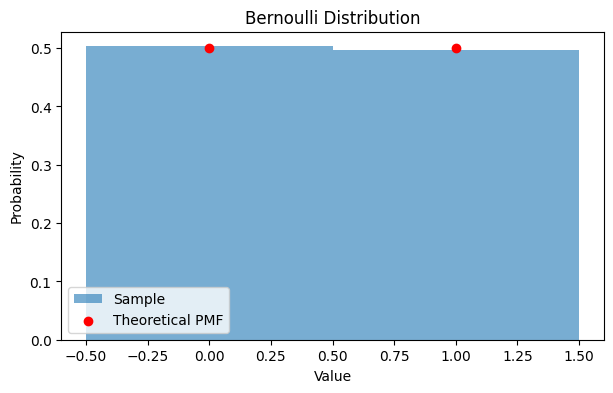

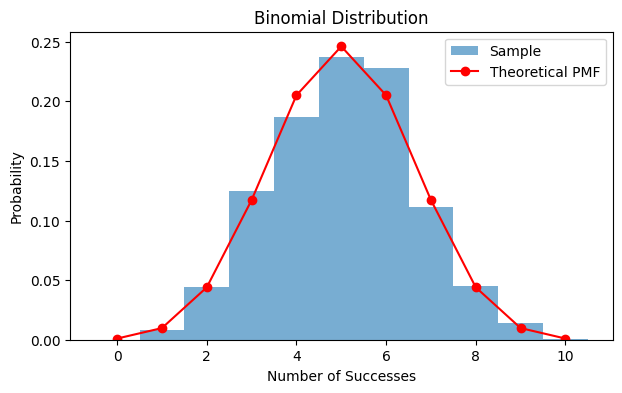

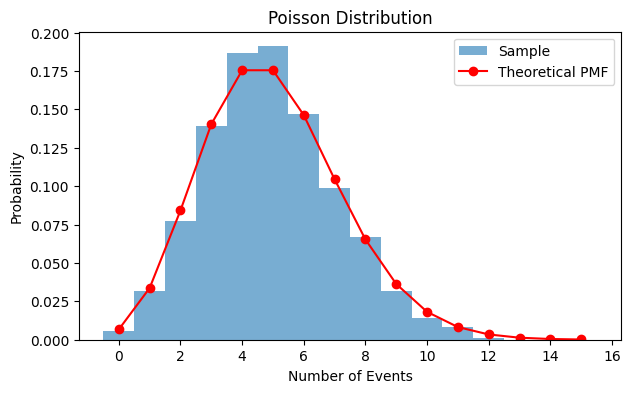

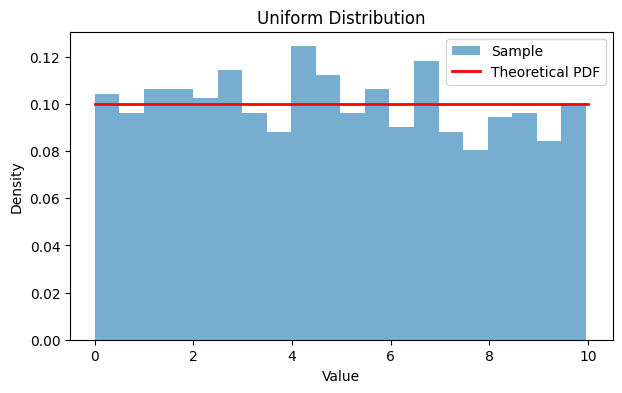

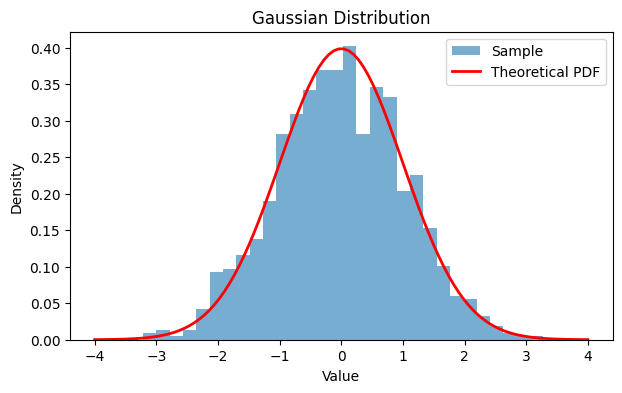


Bayes' Theorem Calculation
Disease Prevalence: 0.01
Sensitivity: 0.95
Specificity: 0.9
Probability of Disease Given Positive Test: 0.0876
Percentage: 8.76 %

Simulation Results
Total Patients: 100000
Patients with Disease: 980
Positive Test Results: 10860
True Positive Results: 929
Empirical Probability:
0.0855
Empirical Percentage: 8.55 %


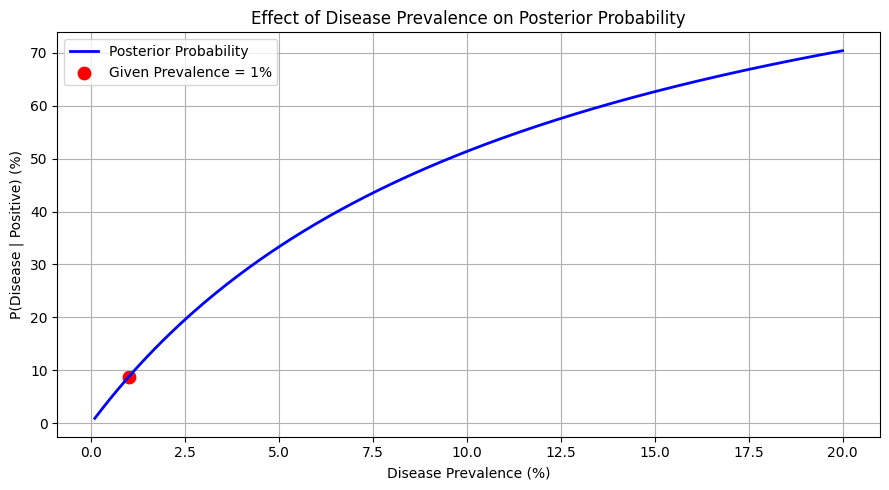

In [4]:

# Experiment 3: Probability Distributions and Bayes' Theorem

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, poisson, uniform, norm

np.random.seed(42)

# ------------------------------------------------
# TASK 1: Generate and Plot Probability Distributions
# ------------------------------------------------

# 1. Bernoulli Distribution
p = 0.5
bernoulli_data = bernoulli.rvs(p, size=1000)

plt.figure(figsize=(7, 4))
x = [0, 1]

plt.hist(bernoulli_data, bins=[-0.5, 0.5, 1.5],
         density=True, alpha=0.6, label='Sample')

plt.scatter(x, bernoulli.pmf(x, p),
            color='red', label='Theoretical PMF')

plt.title("Bernoulli Distribution")
plt.xlabel("Value")
plt.ylabel("Probability")
plt.legend()
plt.show()


# 2. Binomial Distribution
n = 10
p = 0.5

binomial_data = binom.rvs(n, p, size=1000)

plt.figure(figsize=(7, 4))

x = np.arange(0, n + 1)

plt.hist(binomial_data, bins=np.arange(-0.5, n + 1.5, 1),
         density=True, alpha=0.6, label='Sample')

plt.plot(x, binom.pmf(x, n, p),
         'ro-', label='Theoretical PMF')

plt.title("Binomial Distribution")
plt.xlabel("Number of Successes")
plt.ylabel("Probability")
plt.legend()
plt.show()


# 3. Poisson Distribution
mu = 5

poisson_data = poisson.rvs(mu, size=1000)

plt.figure(figsize=(7, 4))

x = np.arange(0, 16)

plt.hist(poisson_data, bins=np.arange(-0.5, 16.5, 1),
         density=True, alpha=0.6, label='Sample')

plt.plot(x, poisson.pmf(x, mu),
         'ro-', label='Theoretical PMF')

plt.title("Poisson Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Probability")
plt.legend()
plt.show()


# 4. Uniform Distribution
a, b = 0, 10

uniform_data = uniform.rvs(loc=a, scale=b-a, size=1000)

plt.figure(figsize=(7, 4))

x = np.linspace(a, b, 100)

plt.hist(uniform_data, bins=20, density=True,
         alpha=0.6, label='Sample')

plt.plot(x, uniform.pdf(x, loc=a, scale=b-a),
         'r-', linewidth=2, label='Theoretical PDF')

plt.title("Uniform Distribution")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()


# 5. Gaussian / Normal Distribution
mean = 0
std = 1

normal_data = norm.rvs(loc=mean, scale=std, size=1000)

plt.figure(figsize=(7, 4))

x = np.linspace(-4, 4, 100)

plt.hist(normal_data, bins=30, density=True,
         alpha=0.6, label='Sample')

plt.plot(x, norm.pdf(x, loc=mean, scale=std),
         'r-', linewidth=2, label='Theoretical PDF')

plt.title("Gaussian Distribution")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()


# ------------------------------------------------
# TASK 2: Bayes' Theorem
# ------------------------------------------------

# Given probabilities
prevalence = 0.01
sensitivity = 0.95
specificity = 0.90

# Probability of positive result for a healthy person
false_positive_rate = 1 - specificity

# Bayes' theorem
p_disease_given_positive = (
    sensitivity * prevalence
) / (
    sensitivity * prevalence +
    false_positive_rate * (1 - prevalence)
)

print("\nBayes' Theorem Calculation")

print("Disease Prevalence:", prevalence)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

print("Probability of Disease Given Positive Test:",
      round(p_disease_given_positive, 4))

print("Percentage:",
      round(p_disease_given_positive * 100, 2), "%")


# ------------------------------------------------
# TASK 3: Simulate 100,000 Patients
# ------------------------------------------------

N = 100000

# Generate disease status
disease = np.random.binomial(1, prevalence, N)

# Generate test results
test_positive = np.zeros(N, dtype=int)

for i in range(N):
    if disease[i] == 1:
        # Diseased patient: 95% chance of positive result
        test_positive[i] = np.random.binomial(1, sensitivity)
    else:
        # Healthy patient: 10% chance of false positive
        test_positive[i] = np.random.binomial(
            1, false_positive_rate
        )

# Count positive test results
total_positive = np.sum(test_positive)

# Count true positive results
true_positive = np.sum(
    (disease == 1) & (test_positive == 1)
)

# Empirical posterior probability
empirical_probability = true_positive / total_positive

print("\nSimulation Results")

print("Total Patients:", N)
print("Patients with Disease:", np.sum(disease))
print("Positive Test Results:", total_positive)
print("True Positive Results:", true_positive)

print("Empirical Probability:")
print(round(empirical_probability, 4))

print("Empirical Percentage:",
      round(empirical_probability * 100, 2), "%")


# ------------------------------------------------
# TASK 4: Effect of Prevalence on Posterior Probability
# ------------------------------------------------

prevalence_values = np.linspace(0.001, 0.20, 200)

posterior_values = (
    sensitivity * prevalence_values
) / (
    sensitivity * prevalence_values +
    false_positive_rate * (1 - prevalence_values)
)

plt.figure(figsize=(9, 5))

plt.plot(
    prevalence_values * 100,
    posterior_values * 100,
    color='blue',
    linewidth=2,
    label='Posterior Probability'
)

# Mark original prevalence = 1%
plt.scatter(
    [1],
    [p_disease_given_positive * 100],
    color='red',
    s=80,
    label='Given Prevalence = 1%'
)

plt.xlabel("Disease Prevalence (%)")
plt.ylabel("P(Disease | Positive) (%)")

plt.title("Effect of Disease Prevalence on Posterior Probability")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
